# Engagement Prediction Model

Random Forest regression to predict engagement per audience segment, plus robustness checks.

In [1]:
from pathlib import Path
import pandas as pd

# works from notebooks/ (Jupyter) or the repo root (e.g. Colab after git clone + %cd)
DATA_DIR = Path('../data') if Path('../data').exists() else Path('data')

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import random
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
%matplotlib inline

In [3]:
ad_df,user_df,ad_events_df,campaigns_df = pd.read_csv(DATA_DIR / 'ads.csv'),pd.read_csv(DATA_DIR / 'users.csv'),pd.read_csv(DATA_DIR / 'ad_events.csv'),pd.read_csv(DATA_DIR / 'campaigns.csv')

In [4]:
ad_events_df

,event_id,ad_id,user_id,timestamp,day_of_week,time_of_day,event_type
0,1,197,2359b,2025-07-26 00:19:56,Saturday,Night,Like
1,2,51,f9c67,2025-06-15 08:28:07,Sunday,Morning,Share
2,3,46,5b868,2025-06-27 00:40:02,Friday,Night,Impression
3,4,166,3d440,2025-06-05 19:20:45,Thursday,Evening,Impression
4,5,52,68f1a,2025-07-22 08:30:29,Tuesday,Morning,Impression
...,...,...,...,...,...,...,...
399995,399996,132,3cb8c,2025-08-01 22:36:54,Friday,Evening,Impression
399996,399997,200,fe0e3,2025-05-31 14:53:18,Saturday,Afternoon,Impression
399997,399998,2,a08c1,2025-07-27 13:39:51,Sunday,Afternoon,Click
399998,399999,109,4f0cf,2025-05-16 02:38:23,Friday,Night,Impression


In [5]:
ad_df

,ad_id,campaign_id,ad_platform,ad_type,target_gender,target_age_group,target_interests
0,1,28,Facebook,Video,Female,35-44,"art, technology"
1,2,33,Facebook,Stories,All,25-34,"travel, photography"
2,3,20,Instagram,Carousel,All,25-34,technology
3,4,28,Facebook,Stories,Female,25-34,news
4,5,24,Instagram,Image,Female,25-34,news
...,...,...,...,...,...,...,...
195,196,12,Facebook,Stories,Male,35-44,"gaming, sports"
196,197,9,Facebook,Stories,All,All,"lifestyle, gaming"
197,198,34,Facebook,Video,All,35-44,"fitness, lifestyle"
198,199,15,Instagram,Video,Male,25-34,"art, news"


In [6]:
user_df

,user_id,user_gender,user_age,age_group,country,location,interests
0,a2474,Female,24,18-24,United Kingdom,New Mariomouth,"fitness, health"
1,141e5,Male,21,18-24,Germany,Danielsfort,"food, fitness, lifestyle"
2,34db0,Male,27,25-34,Australia,Vincentchester,"fashion, news"
3,20d08,Female,28,25-34,India,Lisaport,"health, news, finance"
4,9e830,Male,28,25-34,United States,Brownmouth,"health, photography, lifestyle"
...,...,...,...,...,...,...,...
9995,24364,Male,18,18-24,United States,Curtisside,"travel, fashion, art"
9996,68b82,Male,24,18-24,Mexico,Brownland,finance
9997,39f39,Male,29,25-34,United States,Watersburgh,health
9998,0b8e7,Male,31,25-34,United Kingdom,South Kenneth,"art, fashion"


In [7]:
ads_df_clean = ad_df.drop_duplicates(subset=['ad_id'])
users_df_clean = user_df.drop_duplicates(subset=['user_id'])
campaigns_df_clean = campaigns_df.drop_duplicates(subset=['campaign_id'])

ad_events_df['timestamp'] = pd.to_datetime(ad_events_df['timestamp'])
ad_events_df['hour_of_day'] = ad_events_df['timestamp'].dt.hour
campaigns_df_clean['start_date'] = pd.to_datetime(campaigns_df_clean['start_date'])
campaigns_df_clean['end_date'] = pd.to_datetime(campaigns_df_clean['end_date'])

campaigns_df_clean['start_month'] = campaigns_df_clean['start_date'].dt.month
campaigns_df_clean['start_day'] = campaigns_df_clean['start_date'].dt.day
campaigns_df_clean['end_month'] = campaigns_df_clean['end_date'].dt.month
campaigns_df_clean['end_day'] = campaigns_df_clean['end_date'].dt.day

df_merged = pd.merge(ad_events_df, ads_df_clean, on='ad_id', how='left')

df_merged = pd.merge(
    df_merged,
    campaigns_df_clean[['campaign_id', 'name', 'duration_days', 'start_month', 'start_day', 'end_month', 'end_day']],
    on='campaign_id',
    how='left'
).rename(columns={'name': 'campaign_name'})

df_merged = pd.merge(
    df_merged,
    users_df_clean[['user_id', 'user_gender', 'age_group']],
    on='user_id',
    how='left'
)
df_merged

,event_id,ad_id,user_id,timestamp,day_of_week,time_of_day,event_type,hour_of_day,campaign_id,ad_platform,...,target_age_group,target_interests,campaign_name,duration_days,start_month,start_day,end_month,end_day,user_gender,age_group
0,1,197,2359b,2025-07-26 00:19:56,Saturday,Night,Like,0,9,Facebook,...,All,"lifestyle, gaming",Campaign_9_Launch,49,5,25,7,13,Female,18-24
1,2,51,f9c67,2025-06-15 08:28:07,Sunday,Morning,Share,8,26,Instagram,...,18-24,photography,Campaign_26_Winter,77,4,1,6,17,Female,25-34
2,3,46,5b868,2025-06-27 00:40:02,Friday,Night,Impression,0,10,Instagram,...,35-44,"technology, travel",Campaign_10_Winter,65,5,17,7,21,Male,18-24
3,4,166,3d440,2025-06-05 19:20:45,Thursday,Evening,Impression,19,14,Instagram,...,All,fashion,Campaign_14_Summer,50,4,15,6,4,Female,18-24
4,5,52,68f1a,2025-07-22 08:30:29,Tuesday,Morning,Impression,8,2,Instagram,...,35-44,"health, lifestyle",Campaign_2_Launch,82,4,16,7,7,Male,55-65
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
399995,399996,132,3cb8c,2025-08-01 22:36:54,Friday,Evening,Impression,22,1,Facebook,...,18-24,news,Campaign_1_Launch,59,5,25,7,23,Male,16-17
399996,399997,200,fe0e3,2025-05-31 14:53:18,Saturday,Afternoon,Impression,14,44,Instagram,...,18-24,photography,Campaign_44_Q3,70,7,14,9,22,Male,25-34
399997,399998,2,a08c1,2025-07-27 13:39:51,Sunday,Afternoon,Click,13,33,Facebook,...,25-34,"travel, photography",Campaign_33_Summer,87,4,8,7,4,Female,25-34
399998,399999,109,4f0cf,2025-05-16 02:38:23,Friday,Night,Impression,2,8,Facebook,...,35-44,"travel, fashion",Campaign_8_Q3,41,2,25,4,7,Other,25-34


## regression

### เตรียมข้อมูล

In [8]:
df_grouped = df_merged.groupby(['day_of_week', 'ad_platform', 'ad_type', 'target_gender', 'user_gender','target_age_group', 'age_group']).agg(
    engaged=('event_type', 'count')
).reset_index()

final_columns_for_ml = [
    'day_of_week',
    'ad_platform',
    'ad_type',
    'target_gender',
    'user_gender',
    'target_age_group',
    'age_group',
    'engaged'
]

df_final_ml_ready = df_grouped[final_columns_for_ml].copy()

display(df_final_ml_ready)

,day_of_week,ad_platform,ad_type,target_gender,user_gender,target_age_group,age_group,engaged
0,Friday,Facebook,Carousel,All,Female,18-24,16-17,22
1,Friday,Facebook,Carousel,All,Female,18-24,18-24,88
2,Friday,Facebook,Carousel,All,Female,18-24,25-34,133
3,Friday,Facebook,Carousel,All,Female,18-24,35-44,34
4,Friday,Facebook,Carousel,All,Female,18-24,45-54,15
...,...,...,...,...,...,...,...,...
9721,Wednesday,Instagram,Video,Male,Male,25-34,55-65,1
9722,Wednesday,Instagram,Video,Male,Other,25-34,16-17,4
9723,Wednesday,Instagram,Video,Male,Other,25-34,18-24,8
9724,Wednesday,Instagram,Video,Male,Other,25-34,25-34,13


In [9]:
df_final_ml_ready.sort_values(by='engaged', ascending=False)

,day_of_week,ad_platform,ad_type,target_gender,user_gender,target_age_group,age_group,engaged
4633,Sunday,Facebook,Stories,Female,Male,18-24,25-34,629
1859,Monday,Facebook,Stories,Female,Male,18-24,25-34,601
3241,Saturday,Facebook,Stories,Female,Male,18-24,25-34,596
7416,Tuesday,Facebook,Stories,Female,Male,18-24,25-34,595
8803,Wednesday,Facebook,Stories,Female,Male,18-24,25-34,591
...,...,...,...,...,...,...,...,...
8131,Tuesday,Instagram,Stories,All,Other,18-24,45-54,1
185,Friday,Facebook,Carousel,Male,Other,All,16-17,1
189,Friday,Facebook,Carousel,Male,Other,All,55-65,1
206,Friday,Facebook,Image,All,Female,35-44,45-54,1


In [10]:
df_final_ml_ready = df_final_ml_ready.drop(4633)

In [11]:
df_final_ml_ready

,day_of_week,ad_platform,ad_type,target_gender,user_gender,target_age_group,age_group,engaged
0,Friday,Facebook,Carousel,All,Female,18-24,16-17,22
1,Friday,Facebook,Carousel,All,Female,18-24,18-24,88
2,Friday,Facebook,Carousel,All,Female,18-24,25-34,133
3,Friday,Facebook,Carousel,All,Female,18-24,35-44,34
4,Friday,Facebook,Carousel,All,Female,18-24,45-54,15
...,...,...,...,...,...,...,...,...
9721,Wednesday,Instagram,Video,Male,Male,25-34,55-65,1
9722,Wednesday,Instagram,Video,Male,Other,25-34,16-17,4
9723,Wednesday,Instagram,Video,Male,Other,25-34,18-24,8
9724,Wednesday,Instagram,Video,Male,Other,25-34,25-34,13


In [12]:
X = df_final_ml_ready.drop('engaged', axis=1)
y = df_final_ml_ready['engaged']

In [13]:
X

,day_of_week,ad_platform,ad_type,target_gender,user_gender,target_age_group,age_group
0,Friday,Facebook,Carousel,All,Female,18-24,16-17
1,Friday,Facebook,Carousel,All,Female,18-24,18-24
2,Friday,Facebook,Carousel,All,Female,18-24,25-34
3,Friday,Facebook,Carousel,All,Female,18-24,35-44
4,Friday,Facebook,Carousel,All,Female,18-24,45-54
...,...,...,...,...,...,...,...
9721,Wednesday,Instagram,Video,Male,Male,25-34,55-65
9722,Wednesday,Instagram,Video,Male,Other,25-34,16-17
9723,Wednesday,Instagram,Video,Male,Other,25-34,18-24
9724,Wednesday,Instagram,Video,Male,Other,25-34,25-34


In [14]:
y

0        22
1        88
2       133
3        34
4        15
       ... 
9721      1
9722      4
9723      8
9724     13
9725      6
Name: engaged, Length: 9725, dtype: int64

In [15]:
# Identify categorical columns
categorical_features_reg = ['day_of_week', 'ad_platform', 'ad_type', 'target_gender', 'user_gender', 'target_age_group', 'age_group']

# Create a column transformer for one-hot encoding
preprocessor_reg = ColumnTransformer(
    transformers=[
        ('onehot', OneHotEncoder(handle_unknown='ignore'), categorical_features_reg)
    ],
    remainder='passthrough' # Keep the rest of the columns (which is 'engaged' in this case)
)

# # Separate features (X) and target (y)
# X_reg = df_engaged_by_day.drop('engaged', axis=1)
# y_reg = df_engaged_by_day['engaged']

# # Apply the preprocessing to the data
# X_reg_processed = preprocessor_reg.fit_transform(X_reg)

# # Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# print("Shape of X_train_reg:", X_train_reg.shape)
# print("Shape of X_test_reg:", X_test_reg.shape)
# print("Shape of y_train_reg:", y_train_reg.shape)
# print("Shape of y_test_reg:", y_test_reg.shape)

### Model

In [16]:
pipeline_1 = Pipeline([
    ('preprocessor', preprocessor_reg),
    ('model', RandomForestRegressor(n_estimators=200, random_state=42))
])

In [17]:
pipeline_2 = Pipeline([
    ('preprocessor', preprocessor_reg),
    ('model', RandomForestRegressor(n_estimators=200, random_state=42))
])

In [18]:
pipeline_1

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('onehot', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the out

In [19]:
pipeline_1.fit(X_train, y_train)
# Make predictions on the test set
y_pred_reg = pipeline_1.predict(X_test)

In [20]:
pipeline_2.fit(X_train, y_train)
# Make predictions on the test set
y_pred_reg_train = pipeline_2.predict(X_train)

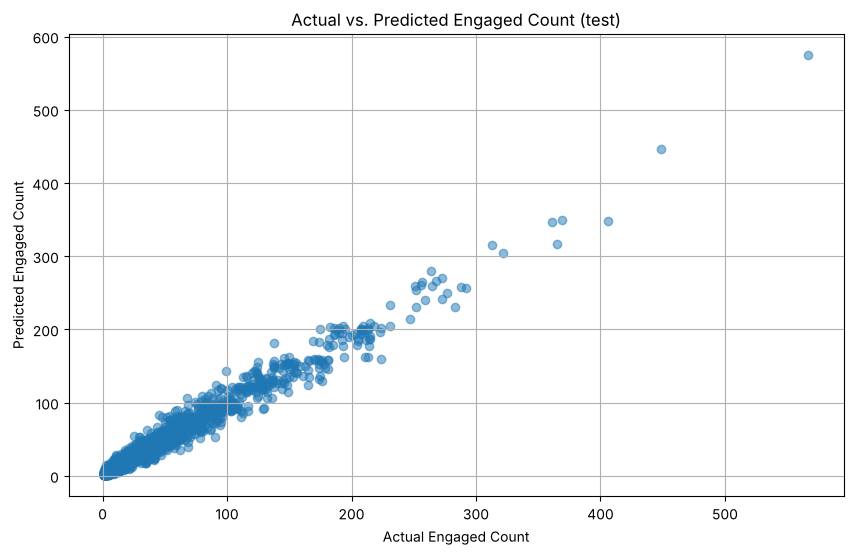

In [21]:
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred_reg, alpha=0.5)
plt.xlabel("Actual Engaged Count")
plt.ylabel("Predicted Engaged Count")
plt.title("Actual vs. Predicted Engaged Count (test)")
plt.grid(True)
plt.show()

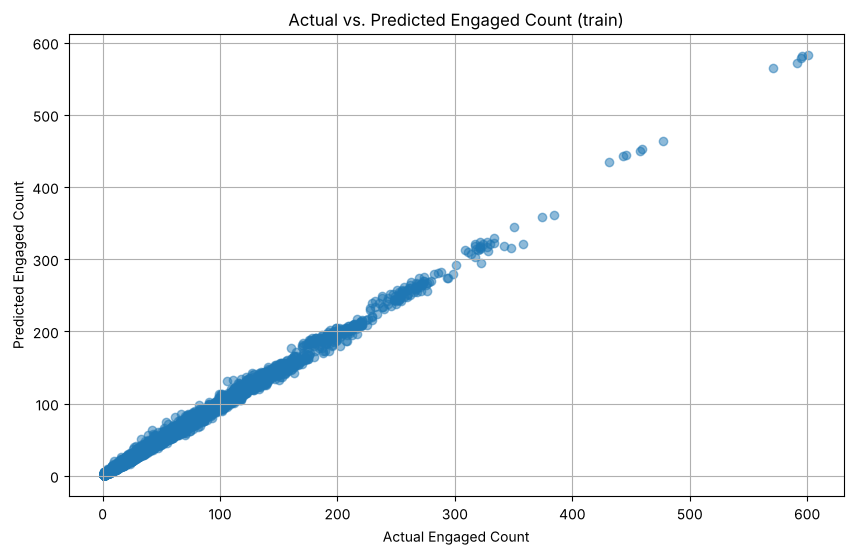

In [22]:
plt.figure(figsize=(10, 6))
plt.scatter(y_train, y_pred_reg_train, alpha=0.5)
plt.xlabel("Actual Engaged Count")
plt.ylabel("Predicted Engaged Count")
plt.title("Actual vs. Predicted Engaged Count (train)")
plt.grid(True)
plt.show()

In [23]:
# Calculate regression metrics
mae = mean_absolute_error(y_test, y_pred_reg)
mse = mean_squared_error(y_test, y_pred_reg)
rmse = np.sqrt(mse) # Calculate Root Mean Squared Error as well
r2 = r2_score(y_test, y_pred_reg)

# Display the metrics
print('test\n------------------------------------')
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared (R2): {r2:.2f}")

test
------------------------------------
Mean Absolute Error (MAE): 5.89
Mean Squared Error (MSE): 87.19
Root Mean Squared Error (RMSE): 9.34
R-squared (R2): 0.97


In [24]:
# Calculate regression metrics
mae = mean_absolute_error(y_train, y_pred_reg_train)
mse = mean_squared_error(y_train, y_pred_reg_train)
rmse = np.sqrt(mse) # Calculate Root Mean Squared Error as well
r2 = r2_score(y_train, y_pred_reg_train)

# Display the metrics
print('train\n------------------------------------')
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared (R2): {r2:.2f}")

train
------------------------------------
Mean Absolute Error (MAE): 2.14
Mean Squared Error (MSE): 11.92
Root Mean Squared Error (RMSE): 3.45
R-squared (R2): 1.00


## Test Model

In [25]:
'Sunday	Facebook	Stories	Female	Male	18-24	25-34'

'Sunday\tFacebook\tStories\tFemale\tMale\t18-24\t25-34'

In [26]:
new_data = pd.DataFrame({
    'day_of_week': ['Monday'],
    'ad_platform': ['Instagram'],
    'ad_type': ['Stories'],
    'target_gender': ['All'],
    'user_gender': ['Other'],
    'target_age_group': ['18-24'],
    'age_group': ['55-65']
})

display(new_data)

,day_of_week,ad_platform,ad_type,target_gender,user_gender,target_age_group,age_group
0,Monday,Instagram,Stories,All,Other,18-24,55-65


In [27]:
print(pipeline_1.predict(new_data))

[1.205]


======================================================================
🔍 สรุปผลการวิเคราะห์แบบถดถอย (Regression Analysis Summary)
======================================================================

📈 ประสิทธิภาพของโมเดล (Model Performance):
• ค่า R-squared (R²): 0.97 → โมเดลสามารถอธิบายความแปรปรวนของการมีส่วนร่วมได้ถึง 97%
• ค่า Mean Absolute Error (MAE): 5.89 → โมเดลทำนายคลาดเคลื่อนจากค่าจริงโดยเฉลี่ยประมาณ 5.9 ครั้งของการมีส่วนร่วม
• ค่า Mean Squared Error (MSE): 87.19
• ค่า Root Mean Squared Error (RMSE): 9.34
→ ค่าความคลาดเคลื่อนที่ต่ำ แสดงให้เห็นว่าโมเดลมีความแม่นยำสูง

⭐ ตัวแปรที่มีอิทธิพลต่อการมีส่วนร่วม (Feature Importance):
• ปัจจัยที่มีอิทธิพลสูงสุด:
   - ช่วงอายุผู้ใช้: 25–34 และ 18–24 ปี
   - เพศ: 'Other' และ 'Male'
• ประเภทโฆษณา (Ad Type): 'Stories' มีผลต่อการมีส่วนร่วมสูง
• กลุ่มเป้าหมาย (Target Audience):
   - ช่วงอายุเป้าหมาย: 18–24 ปี
   - เพศเป้าหมาย: ชาย (Male) และ หญิง (Female)
• วันในสัปดาห์: มีผลกระทบน้อยที่สุดต่อการมีส่วนร่วม

💡 ข้อเสนอแนะเชิงกลยุทธ์ (Strategic Insights):
• ควรเน้นการโฆษณาในกลุ่มอายุ 18–34 ปี
• ใช้ประเภทโฆษณาแบบ 'Stories' เพื่อเพิ่มการมีส่วนร่วม
• ปรับเนื้อหาให้เหมาะสมกับเพศชายและเพศอื่น ๆ (Other)
• วันในสัปดาห์มีผลน้อย จึงไม่จำเป็นต้องโฟกัสมากนัก

✅ สรุปผลโดยรวม (Conclusion):
โมเดลนี้มีความแม่นยำสูง (R² = 0.97) และแสดงให้เห็นว่า ปัจจัยเรื่องอายุ เพศ และประเภทโฆษณา
มีอิทธิพลต่อจำนวนการมีส่วนร่วมอย่างชัดเจน ข้อมูลเชิงลึกเหล่านี้สามารถนำไปใช้วางแผนกลยุทธ์
การยิงโฆษณาให้ตรงกลุ่มเป้าหมาย เพื่อเพิ่มประสิทธิภาพของการมีส่วนร่วมได้สูงสุด
======================================================================


# Correlation

In [28]:
# Get feature importances from the trained model
feature_importances = pipeline_1.named_steps['model'].feature_importances_

# Get feature names from the one-hot encoder
onehot_features = pipeline_1.named_steps['preprocessor'].named_transformers_['onehot'].get_feature_names_out(categorical_features_reg)

# Create a pandas Series for better visualization
feature_importance_series = pd.Series(feature_importances, index=onehot_features)

# Sort the features by importance
sorted_feature_importances = feature_importance_series.sort_values(ascending=False)

# Display the sorted feature importances
print("Feature Importances:")
print(sorted_feature_importances)

Feature Importances:
age_group_25-34           0.204733
user_gender_Other         0.163737
age_group_18-24           0.133713
user_gender_Male          0.080681
target_age_group_18-24    0.048887
ad_type_Stories           0.045953
target_gender_Male        0.032069
target_age_group_35-44    0.030738
target_gender_Female      0.030614
user_gender_Female        0.029752
target_gender_All         0.023856
target_age_group_All      0.023363
target_age_group_25-34    0.021004
age_group_35-44           0.020639
ad_type_Carousel          0.020617
ad_platform_Instagram     0.019450
ad_platform_Facebook      0.018611
ad_type_Image             0.015516
ad_type_Video             0.012613
age_group_16-17           0.006969
day_of_week_Tuesday       0.002355
day_of_week_Monday        0.002335
day_of_week_Wednesday     0.002317
day_of_week_Saturday      0.002314
day_of_week_Thursday      0.002220
day_of_week_Friday        0.002153
day_of_week_Sunday        0.002094
age_group_45-54           0.000372

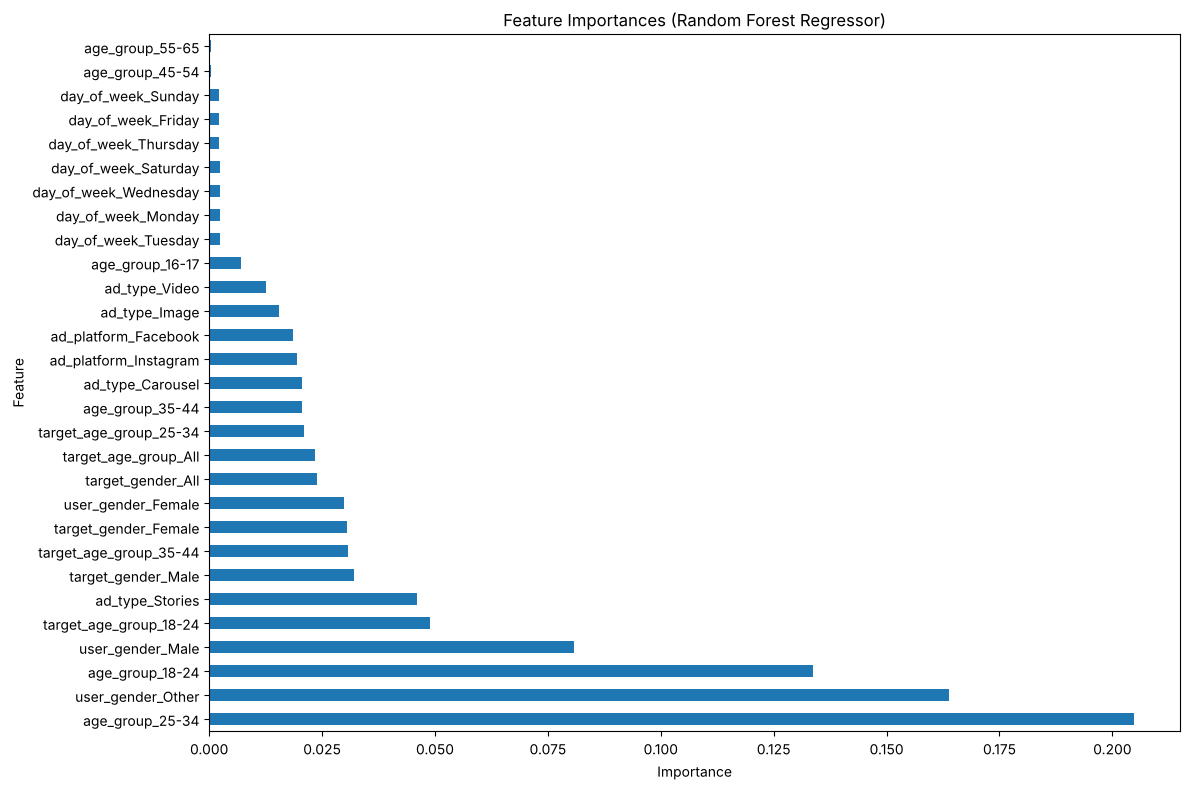

In [29]:
# Plot the feature importances
plt.figure(figsize=(12, 8))
sorted_feature_importances.plot(kind='barh')
plt.title('Feature Importances (Random Forest Regressor)')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

In [30]:
# Check the relationship between categorical features and the 'engaged' column
categorical_features = df_final_ml_ready.select_dtypes(exclude=np.number).columns.tolist()

for feature in categorical_features:
    print(f"Relationship between '{feature}' and 'engaged':")
    display(df_final_ml_ready.groupby(feature)['engaged'].mean().sort_values(ascending=False))
    print("\n" + "="*50 + "\n")

Relationship between 'day_of_week' and 'engaged':


day_of_week
Monday       41.425470
Tuesday      41.363043
Friday       41.326854
Saturday     41.174729
Wednesday    40.991385
Thursday     40.820000
Sunday       40.373209
Name: engaged, dtype: float64



Relationship between 'ad_platform' and 'engaged':


ad_platform
Facebook     46.126843
Instagram    34.492671
Name: engaged, dtype: float64



Relationship between 'ad_type' and 'engaged':


ad_type
Stories     46.932328
Carousel    40.999598
Image       39.559070
Video       34.828059
Name: engaged, dtype: float64

... (4 outputs left out)



Relationship between 'target_age_group' and 'engaged':


target_age_group
35-44    47.084790
18-24    41.280446
All      39.157761
25-34    37.097738
Name: engaged, dtype: float64



Relationship between 'age_group' and 'engaged':


age_group
25-34    95.876235
18-24    72.314170
35-44    33.722255
16-17    20.627188
45-54     8.152416
55-65     2.671533
Name: engaged, dtype: float64

# **ลอง DROP age_group_55-65 age_group_45-54**



In [31]:
import pandas as pd
# สมมติว่า df_final_ml_ready ถูกสร้างขึ้นตามโค้ดก่อนหน้า
# df_final_ml_ready = ...

# --- 1. กรอง (Filter) แถวที่ไม่ต้องการออกไป ---
# ระบุค่าในคอลัมน์ 'age_group' ที่ต้องการยกเลิก
age_groups_to_exclude = ['55-65', '45-54']

# สร้าง DataFrame ใหม่ที่ไม่มีแถวของกลุ่มอายุ 55-65 และ 45-54
# ใช้เครื่องหมาย ~ (Not) และ .isin()
df_filtered = df_final_ml_ready[
    ~df_final_ml_ready['age_group'].isin(age_groups_to_exclude)
].copy()

print(f"จำนวนแถวก่อนกรอง: {len(df_final_ml_ready)}")
print(f"จำนวนแถวหลังกรอง: {len(df_filtered)}")
print("Unique 'age_group' หลังกรอง:", df_filtered['age_group'].unique())

# --- 2. ทำ One-Hot Encoding สำหรับคอลัมน์หมวดหมู่ (Categorical Columns) บน DataFrame ที่กรองแล้ว ---
# คอลัมน์หมวดหมู่ทั้งหมดที่คุณมี
categorical_cols = [
    'day_of_week',
    'ad_platform',
    'ad_type',
    'target_gender',
    'user_gender',
    'target_age_group',
    'age_group' # คอลัมน์นี้จะถูกแปลงเป็น Dummy Variables ที่ไม่มี 55-65 และ 45-54 แล้ว
]

# สร้าง DataFrame ที่เข้ารหัสแล้ว (Encoded/Dummy Variables)
# เนื่องจากเราได้กรองแถวที่ไม่ต้องการออกไปแล้ว ผลลัพธ์ของ One-Hot Encoding จะไม่มีคอลัมน์ 'age_group_55-65' และ 'age_group_45-54'
df_ml_ready = pd.get_dummies(df_filtered, columns=categorical_cols, drop_first=False)

print("\nColumns in the final ML-ready DataFrame:")
print(df_ml_ready.columns.tolist())

# df_ml_ready คือ DataFrame ใหม่ที่ไม่มีข้อมูลของกลุ่มอายุที่ต้องการยกเลิก และพร้อมนำไปฝึกโมเดลแล้ว

จำนวนแถวก่อนกรอง: 9725
จำนวนแถวหลังกรอง: 6878
Unique 'age_group' หลังกรอง: <StringArray>
['16-17', '18-24', '25-34', '35-44']
Length: 4, dtype: str



Columns in the final ML-ready DataFrame:
['engaged', 'day_of_week_Friday', 'day_of_week_Monday', 'day_of_week_Saturday', 'day_of_week_Sunday', 'day_of_week_Thursday', 'day_of_week_Tuesday', 'day_of_week_Wednesday', 'ad_platform_Facebook', 'ad_platform_Instagram', 'ad_type_Carousel', 'ad_type_Image', 'ad_type_Stories', 'ad_type_Video', 'target_gender_All', 'target_gender_Female', 'target_gender_Male', 'user_gender_Female', 'user_gender_Male', 'user_gender_Other', 'target_age_group_18-24', 'target_age_group_25-34', 'target_age_group_35-44', 'target_age_group_All', 'age_group_16-17', 'age_group_18-24', 'age_group_25-34', 'age_group_35-44']


In [32]:

# 1.1 แยกตัวแปรเป้าหมาย (y) และตัวแปรคุณลักษณะ (X)
# 'engaged' คือคอลัมน์ที่แสดงจำนวนการมีส่วนร่วมที่คุณต้องการทำนาย
X = df_ml_ready.drop('engaged', axis=1)
y = df_ml_ready['engaged']

# 1.2 แบ่งข้อมูลเป็นชุดฝึก (Training) และชุดทดสอบ (Testing)
# test_size=0.2 หมายถึง 20% ของข้อมูลจะถูกใช้ในการทดสอบ
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"ขนาดชุดฝึก (X_train): {X_train.shape}")
print(f"ขนาดชุดทดสอบ (X_test): {X_test.shape}")

ขนาดชุดฝึก (X_train): (5502, 27)
ขนาดชุดทดสอบ (X_test): (1376, 27)


In [33]:

# สร้างและฝึกโมเดล (Training the model)
# ใช้พารามิเตอร์ (Hyperparameters) ที่คุณปรับจูนแล้ว หากมี
rfr_model = RandomForestRegressor(n_estimators=200, random_state=42)
rfr_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [34]:
from sklearn.metrics import mean_squared_error, r2_score

# ทำนายผลบนชุดทดสอบ
y_pred = rfr_model.predict(X_test)

# คำนวณค่า Metric


mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse) # Calculate Root Mean Squared Error as well
r2 = r2_score(y_test, y_pred)

# Display the metrics
print('test drop age_group_55-65 และ age_group_45-54\n------------------------------------')
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared (R2): {r2:.2f}")


test drop age_group_55-65 และ age_group_45-54
------------------------------------
Mean Absolute Error (MAE): 7.25
Mean Squared Error (MSE): 111.17
Root Mean Squared Error (RMSE): 10.54
R-squared (R2): 0.96


In [35]:
# Get feature importances from the trained model
feature_importances = rfr_model.feature_importances_

# Get feature names from the one-hot encoder
# The dataframe X_train already has the one-hot encoded columns
onehot_features = X_train.columns

# Create a pandas Series for better visualization
feature_importance_series = pd.Series(feature_importances, index=onehot_features)

# Sort the features by importance
sorted_feature_importances = feature_importance_series.sort_values(ascending=False)

# Display the sorted feature importances
print("Feature Importances:")
print(sorted_feature_importances)

Feature Importances:
user_gender_Other         0.191036
age_group_25-34           0.178260
age_group_18-24           0.112742
target_age_group_18-24    0.062006
ad_type_Stories           0.055519
user_gender_Male          0.042533
target_gender_Male        0.039936
user_gender_Female        0.036434
target_gender_Female      0.035873
target_age_group_35-44    0.033363
target_gender_All         0.029446
target_age_group_All      0.026865
target_age_group_25-34    0.025552
ad_type_Carousel          0.024648
ad_platform_Facebook      0.023321
ad_platform_Instagram     0.023082
ad_type_Image             0.018806
ad_type_Video             0.015513
age_group_16-17           0.003592
age_group_35-44           0.003317
day_of_week_Saturday      0.002929
day_of_week_Wednesday     0.002749
day_of_week_Tuesday       0.002738
day_of_week_Monday        0.002641
day_of_week_Friday        0.002436
day_of_week_Sunday        0.002342
day_of_week_Thursday      0.002320
dtype: float64


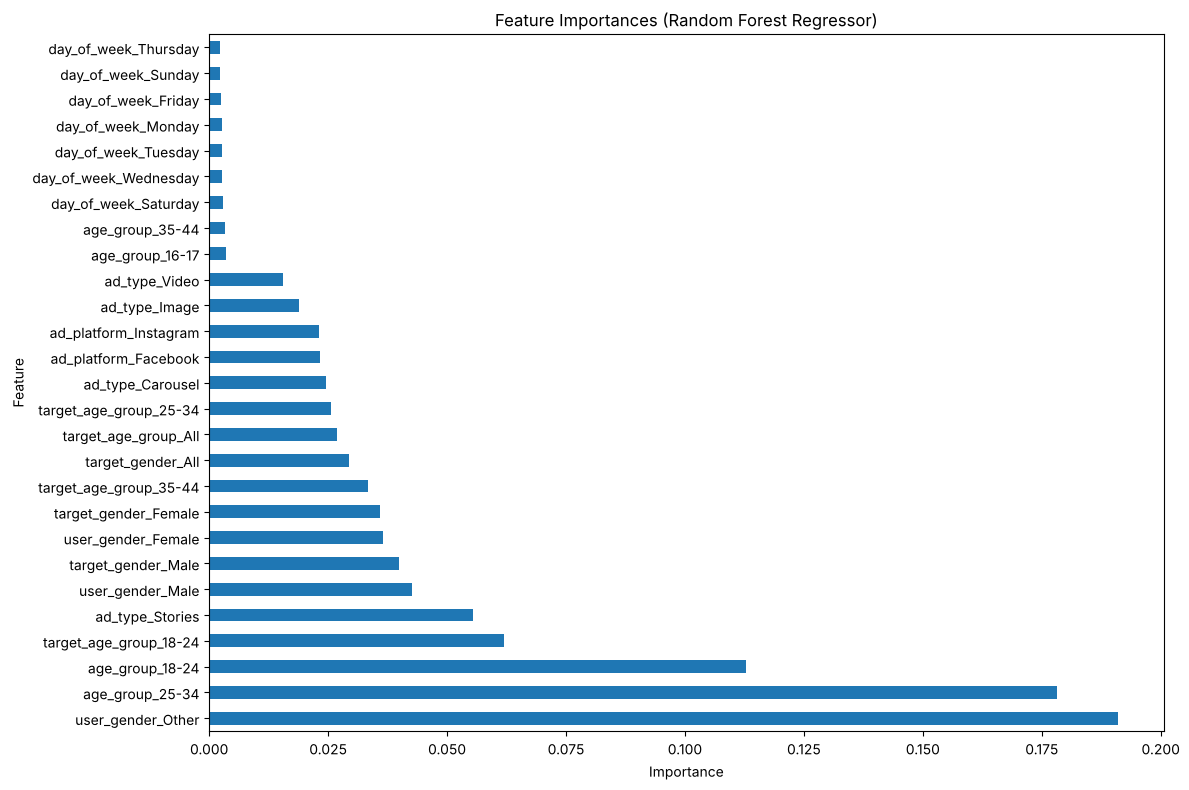

In [36]:
# Plot the feature importances
plt.figure(figsize=(12, 8))
sorted_feature_importances.plot(kind='barh')
plt.title('Feature Importances (Random Forest Regressor)')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

# **เช็ค User_gender_Other เพราะสัดส่วนของ User_gender_Other ใน feature importance มันเยอะเกิน**

In [37]:
# 1.1 นับจำนวนข้อมูลในกลุ่ม 'Other'
count_other = (df_final_ml_ready['user_gender'] == 'Other').sum()

# 1.2 เปรียบเทียบสัดส่วนกับข้อมูลทั้งหมด
total_count = len(df_final_ml_ready)
percentage_other = (count_other / total_count) * 100

print(f"จำนวนแถว 'user_gender_Other': {count_other}")
print(f"สัดส่วนของ 'Other': {percentage_other:.2f}%")

จำนวนแถว 'user_gender_Other': 3036
สัดส่วนของ 'Other': 31.22%


In [38]:
# 2.1 คำนวณค่าเฉลี่ยของ 'engaged' ในแต่ละกลุ่ม
engagement_by_gender = df_final_ml_ready.groupby('user_gender')['engaged'].mean()

print(engagement_by_gender)

user_gender
Female    41.697850
Male      65.227112
Other     13.433465
Name: engaged, dtype: float64


การที่ สัดส่วนข้อมูลของกลุ่มใดกลุ่มหนึ่งมีน้อยมาก (เช่น user_gender_Other) แต่กลับมี ยอด Engagement สูงมาก จนกลายเป็นฟีเจอร์ที่มีความสำคัญสูงสุดในโมเดล (Feature Importance) สามารถแปลความหมายได้สองทางหลัก ๆ ดังนี้:

1. การค้นพบข้อมูลเชิงลึกที่แท้จริง (True Signal / Niche Insight) 💎
นี่คือกรณีที่กลุ่มข้อมูลขนาดเล็กนั้นมีพฤติกรรมที่แตกต่างจากกลุ่มใหญ่มากจริง ๆ และเป็นข้อมูลที่มีคุณค่า:

Conversion / Engagement Rate สูงเป็นพิเศษ: กลุ่มนี้แม้จะมีจำนวนน้อย แต่เมื่อเกิดกิจกรรม (Engagement) พวกเขาทำมันอย่างเข้มข้นหรือบ่อยครั้งมาก นั่นแปลว่าคนกลุ่มนี้มี "ความตั้งใจ" หรือ "ความชอบ" ในเนื้อหาโฆษณาของคุณสูงกว่ากลุ่มอื่น ๆ มาก

นิยามกลุ่มชัดเจน: กลุ่ม "Other" อาจรวมถึงบัญชีธุรกิจ บัญชีที่ใช้ร่วมกัน หรือผู้ใช้งานที่มีแรงจูงใจในการใช้งานแพลตฟอร์มแตกต่างจากผู้ใช้ทั่วไป (Male/Female) ทำให้พฤติกรรมของพวกเขามีผลต่อ Target Variable (engaged) สูงอย่างแท้จริง

โอกาสทางการตลาด: ถ้าเป็นกรณีนี้ มันคือสัญญาณที่ดีว่าคุณได้ค้นพบกลุ่ม Niche ที่มีค่า ซึ่งควรค่าแก่การลงทุนทำแคมเปญโฆษณาแบบเฉพาะเจาะจง (Targeted Campaign)

การที่ สัดส่วนข้อมูลของกลุ่มใดกลุ่มหนึ่งมีน้อยมาก (เช่น user_gender_Other) แต่กลับมี ยอด Engagement สูงมาก จนกลายเป็นฟีเจอร์ที่มีความสำคัญสูงสุดในโมเดล (Feature Importance) สามารถแปลความหมายได้สองทางหลัก ๆ ดังนี้:

1. การค้นพบข้อมูลเชิงลึกที่แท้จริง (True Signal / Niche Insight) 💎
นี่คือกรณีที่กลุ่มข้อมูลขนาดเล็กนั้นมีพฤติกรรมที่แตกต่างจากกลุ่มใหญ่มากจริง ๆ และเป็นข้อมูลที่มีคุณค่า:

Conversion / Engagement Rate สูงเป็นพิเศษ: กลุ่มนี้แม้จะมีจำนวนน้อย แต่เมื่อเกิดกิจกรรม (Engagement) พวกเขาทำมันอย่างเข้มข้นหรือบ่อยครั้งมาก นั่นแปลว่าคนกลุ่มนี้มี "ความตั้งใจ" หรือ "ความชอบ" ในเนื้อหาโฆษณาของคุณสูงกว่ากลุ่มอื่น ๆ มาก

นิยามกลุ่มชัดเจน: กลุ่ม "Other" อาจรวมถึงบัญชีธุรกิจ บัญชีที่ใช้ร่วมกัน หรือผู้ใช้งานที่มีแรงจูงใจในการใช้งานแพลตฟอร์มแตกต่างจากผู้ใช้ทั่วไป (Male/Female) ทำให้พฤติกรรมของพวกเขามีผลต่อ Target Variable (engaged) สูงอย่างแท้จริง

โอกาสทางการตลาด: ถ้าเป็นกรณีนี้ มันคือสัญญาณที่ดีว่าคุณได้ค้นพบกลุ่ม Niche ที่มีค่า ซึ่งควรค่าแก่การลงทุนทำแคมเปญโฆษณาแบบเฉพาะเจาะจง (Targeted Campaign)

2. ข้อมูลผิดปกติ / สัญญาณรบกวน (Noise / Overfitting / Outlier) ⚠️
นี่คือสถานการณ์ที่ข้อมูลนั้นไม่สามารถนำไปใช้สรุปผล (Generalize) กับประชากรส่วนใหญ่ได้ และอาจทำให้โมเดลเข้าใจผิด:

Outlier Effect: ข้อมูลกลุ่มนี้อาจมีเพียงไม่กี่แถวในชุดข้อมูลของคุณ แต่ค่า Engagement ของพวกเขาพุ่งสูงมากผิดปกติ (เช่น มีบัญชีหนึ่งที่คลิก, ไลค์, แชร์ เป็นจำนวนมากในทุก ๆ แคมเปญ) ทำให้โมเดล Random Forest Regressor ให้ความสำคัญกับแถวเหล่านั้นสูงเกินไป

Overfitting: โมเดลเรียนรู้จากความสัมพันธ์เฉพาะเจาะจงที่เกิดจากข้อมูลกลุ่มเล็ก ๆ นี้มากเกินไป เมื่อคุณนำโมเดลนี้ไปใช้กับข้อมูลใหม่ที่ไม่มี Outlier ดังกล่าว ประสิทธิภาพของโมเดลจะตกลงอย่างมาก (Model does not Generalize well).

Data Quality Issue: ค่า "Other" อาจเป็นผลมาจากปัญหาการเก็บข้อมูล หรือการจัดการข้อมูลที่ไม่ถูกต้อง (เช่น ค่า Null ถูกแทนที่ด้วย 'Other' แล้ว Null เหล่านั้นดันไปตรงกับแถวที่มี Engagement สูง)

## **ลอง drop user_gender_Other**


In [39]:
import pandas as pd
# สมมติว่า df_final_ml_ready ถูกสร้างขึ้นตามโค้ดก่อนหน้า
# df_final_ml_ready = ...

# --- 1. กรอง (Filter) แถว 'user_gender_Other' ออกไป ---
# ระบุค่าในคอลัมน์ 'user_gender' ที่ต้องการยกเลิก
user_gender_to_exclude = ['Other']

# แก้ไข: ใช้ชื่อคอลัมน์ 'user_gender' (ตัวเล็กทั้งหมด) ให้ถูกต้อง
df_filtered = df_final_ml_ready[
    ~df_final_ml_ready['user_gender'].isin(user_gender_to_exclude)
].copy()

print(f"จำนวนแถวก่อนกรอง: {len(df_final_ml_ready)}")
print(f"จำนวนแถวหลังกรอง: {len(df_filtered)}")
print("Unique 'user_gender' หลังกรอง:", df_filtered['user_gender'].unique())

# ----------------------------------------------------------------------

# --- 2. ทำ One-Hot Encoding สำหรับคอลัมน์หมวดหมู่ (Categorical Columns) บน DataFrame ที่กรองแล้ว ---
# คอลัมน์หมวดหมู่ทั้งหมดที่คุณมี
categorical_cols = [
    'day_of_week',
    'ad_platform',
    'ad_type',
    'target_gender',
    'user_gender',    # คอลัมน์นี้จะไม่มี 'Other' แล้ว
    'target_age_group',
    'age_group'
]

# สร้าง DataFrame ที่เข้ารหัสแล้ว (Encoded/Dummy Variables)
# ผลลัพธ์ของ One-Hot Encoding จะไม่มีคอลัมน์ 'user_gender_Other'
df_ml_ready = pd.get_dummies(df_filtered, columns=categorical_cols, drop_first=False)

print("\nColumns in the final ML-ready DataFrame:")
print(df_ml_ready.columns.tolist())

# df_ml_ready คือ DataFrame ใหม่ที่ไม่มีข้อมูลของ user_gender_Other และพร้อมนำไปฝึกโมเดลแล้ว

จำนวนแถวก่อนกรอง: 9725
จำนวนแถวหลังกรอง: 6689
Unique 'user_gender' หลังกรอง: <StringArray>
['Female', 'Male']
Length: 2, dtype: str

Columns in the final ML-ready DataFrame:
['engaged', 'day_of_week_Friday', 'day_of_week_Monday', 'day_of_week_Saturday', 'day_of_week_Sunday', 'day_of_week_Thursday', 'day_of_week_Tuesday', 'day_of_week_Wednesday', 'ad_platform_Facebook', 'ad_platform_Instagram', 'ad_type_Carousel', 'ad_type_Image', 'ad_type_Stories', 'ad_type_Video', 'target_gender_All', 'target_gender_Female', 'target_gender_Male', 'user_gender_Female', 'user_gender_Male', 'target_age_group_18-24', 'target_age_group_25-34', 'target_age_group_35-44', 'target_age_group_All', 'age_group_16-17', 'age_group_18-24', 'age_group_25-34', 'age_group_35-44', 'age_group_45-54', 'age_group_55-65']


In [40]:
from sklearn.model_selection import train_test_split

# 1.1 แยกตัวแปรเป้าหมาย (y) และตัวแปรคุณลักษณะ (X)
# 'engaged' คือคอลัมน์ที่แสดงจำนวนการมีส่วนร่วมที่คุณต้องการทำนาย
X = df_ml_ready.drop('engaged', axis=1)
y = df_ml_ready['engaged']

# 1.2 แบ่งข้อมูลเป็นชุดฝึก (Training) และชุดทดสอบ (Testing)
# test_size=0.2 หมายถึง 20% ของข้อมูลจะถูกใช้ในการทดสอบ
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"ขนาดชุดฝึก (X_train): {X_train.shape}")
print(f"ขนาดชุดทดสอบ (X_test): {X_test.shape}")

ขนาดชุดฝึก (X_train): (5351, 28)
ขนาดชุดทดสอบ (X_test): (1338, 28)


In [41]:
from sklearn.ensemble import RandomForestRegressor

# สร้างและฝึกโมเดล (Training the model)
# ใช้พารามิเตอร์ (Hyperparameters) ที่คุณปรับจูนแล้ว หากมี
rfr_model = RandomForestRegressor(n_estimators=200, random_state=42)
rfr_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [42]:
from sklearn.metrics import mean_squared_error, r2_score

# ทำนายผลบนชุดทดสอบ
y_pred = rfr_model.predict(X_test)

# คำนวณค่า Metric


mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse) # Calculate Root Mean Squared Error as well
r2 = r2_score(y_test, y_pred)

# Display the metrics
print('test(drop user_gender_other)\n------------------------------------')
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared (R2): {r2:.2f}")


test(drop user_gender_other)
------------------------------------
Mean Absolute Error (MAE): 6.90
Mean Squared Error (MSE): 103.75
Root Mean Squared Error (RMSE): 10.19
R-squared (R2): 0.97


In [43]:
# Get feature importances from the trained model
feature_importances = rfr_model.feature_importances_

# Get feature names from the one-hot encoder
# The dataframe X_train already has the one-hot encoded columns
onehot_features = X_train.columns

# Create a pandas Series for better visualization
feature_importance_series = pd.Series(feature_importances, index=onehot_features)

# Sort the features by importance
sorted_feature_importances = feature_importance_series.sort_values(ascending=False)

# Display the sorted feature importances
print("Feature Importances:")
print(sorted_feature_importances)

Feature Importances:
age_group_25-34           0.292700
age_group_18-24           0.193882
target_age_group_18-24    0.056201
ad_type_Stories           0.053441
target_gender_Female      0.036184
target_gender_Male        0.036145
user_gender_Female        0.035119
target_age_group_35-44    0.034151
user_gender_Male          0.032501
age_group_35-44           0.027686
target_gender_All         0.026773
target_age_group_All      0.024324
target_age_group_25-34    0.023909
ad_type_Carousel          0.021852
ad_platform_Instagram     0.021656
ad_platform_Facebook      0.020820
ad_type_Image             0.018365
ad_type_Video             0.014165
age_group_16-17           0.012281
day_of_week_Saturday      0.002603
day_of_week_Thursday      0.002450
day_of_week_Wednesday     0.002415
day_of_week_Friday        0.002373
day_of_week_Tuesday       0.002357
day_of_week_Monday        0.002357
day_of_week_Sunday        0.002278
age_group_55-65           0.000528
age_group_45-54           0.000484

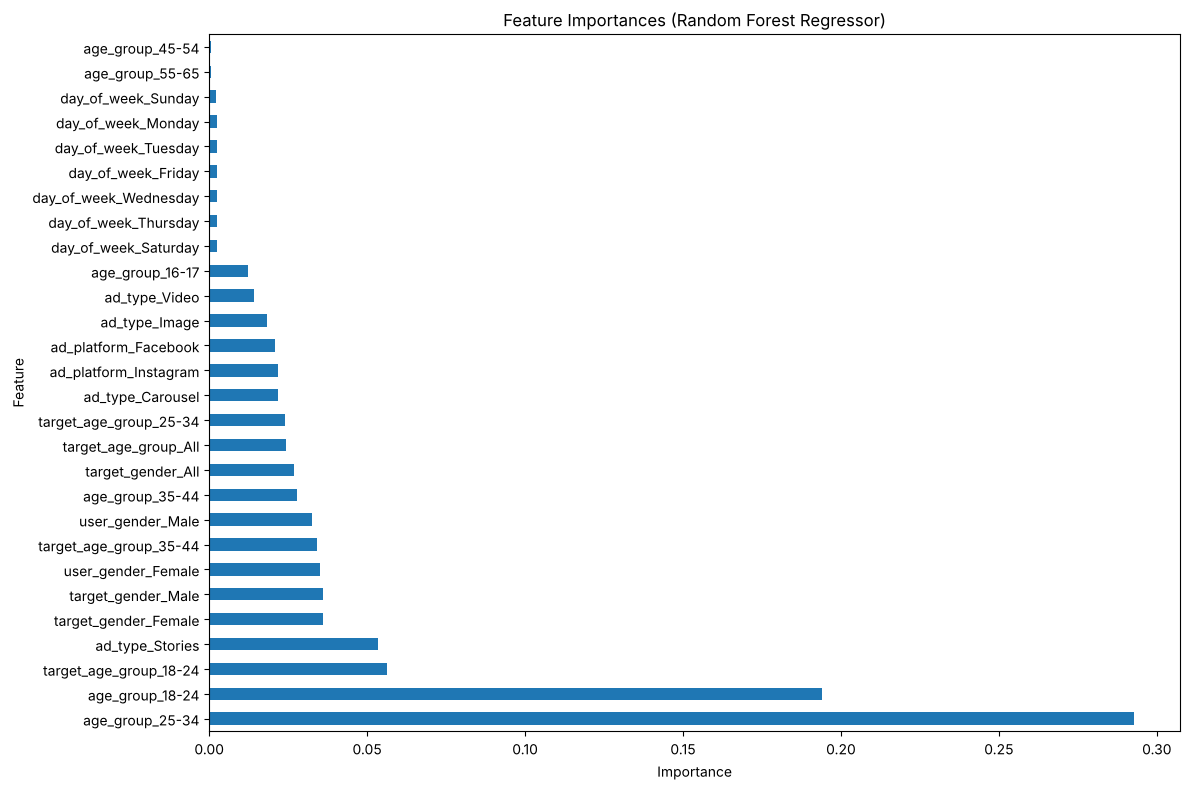

In [44]:
# Plot the feature importances
plt.figure(figsize=(12, 8))
sorted_feature_importances.plot(kind='barh')
plt.title('Feature Importances (Random Forest Regressor)')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

# **Drop**